# Exploratory Data Analysis: Karnataka Hobli Rainfall & Drought Vulnerability

**Project**: Hobli-Level Rainfall Deviation and Drought-Risk Prediction for Karnataka Using Machine Learning  
**Dataset**: KSNDMC (Karnataka State Natural Disaster Monitoring Centre) annual rainfall reports (2020–2025)  
**Input**: `data/clean/clean_rainfall.csv` (3,088 rows)  

This notebook performs comprehensive exploratory data analysis, investigating:
1. Average rainfall across observation years (statewide normal vs actual)
2. 10 driest and 10 wettest districts in Karnataka
3. Distribution and skewness of annual rainfall departure percentages
4. Hoblis experiencing persistent rainfall deficits across multiple years
5. District-by-year spatio-temporal departure heatmap
6. In-depth data quality audit (outliers, missing years/hoblis, impossible values)


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

# Matplotlib visual styling
plt.style.use('default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 12

# File resolution
data_path = 'data/clean/clean_rainfall.csv' if os.path.exists('data/clean/clean_rainfall.csv') else '../data/clean/clean_rainfall.csv'
df = pd.read_csv(data_path)

print(f"Loaded {len(df):,} records across {df['year'].nunique()} years from {data_path}")
print(f"Districts: {df['district'].nunique()} | Taluks: {df['taluk'].nunique()} | Unique Hobli names: {df['hobli'].nunique()}")
print(f"Columns: {list(df.columns)}")
display(df.head(5))


Matplotlib is building the font cache; this may take a moment.


Loaded 3,088 records across 5 years from data/clean/clean_rainfall.csv
Districts: 31 | Taluks: 292 | Unique Hobli names: 587
Columns: ['district', 'taluk', 'hobli', 'year', 'normal_mm', 'actual_mm', 'departure_pct', 'rain_class']


,district,taluk,hobli,year,normal_mm,actual_mm,departure_pct,rain_class
0,BAGALKOTE,Badami,Kerur,2020,569.7,615.1,7.97,NaN
1,BAGALKOTE,Badami,Kulgeri,2020,582.5,625.8,7.43,NaN
2,BAGALKOTE,Bagalkote,Rampura,2020,611.7,642.6,5.05,NaN
3,BAGALKOTE,Bilgi,Anagvadi,2020,598.7,480.2,-19.79,NaN
4,BAGALKOTE,Hungund,Amingarh,2020,632.6,696.3,10.07,NaN


## 1. Average Rainfall by Year

Comparison of statewide mean normal baseline rainfall vs. actual recorded rainfall across all 5 observation years (2020, 2021, 2022, 2023, 2025).


=== Statewide Annual Rainfall Summary ===
 year mean_normal_mm mean_actual_mm mean_departure_pct hobli_count
 2020     1070.77 mm     1282.49 mm            +19.77%         618
 2021     1068.79 mm     1291.63 mm            +30.32%         617
 2022     1068.79 mm     1236.12 mm            +21.87%         617
 2023     1068.79 mm     1477.64 mm            +54.60%         617
 2025     1069.79 mm     1220.04 mm            +13.56%         619


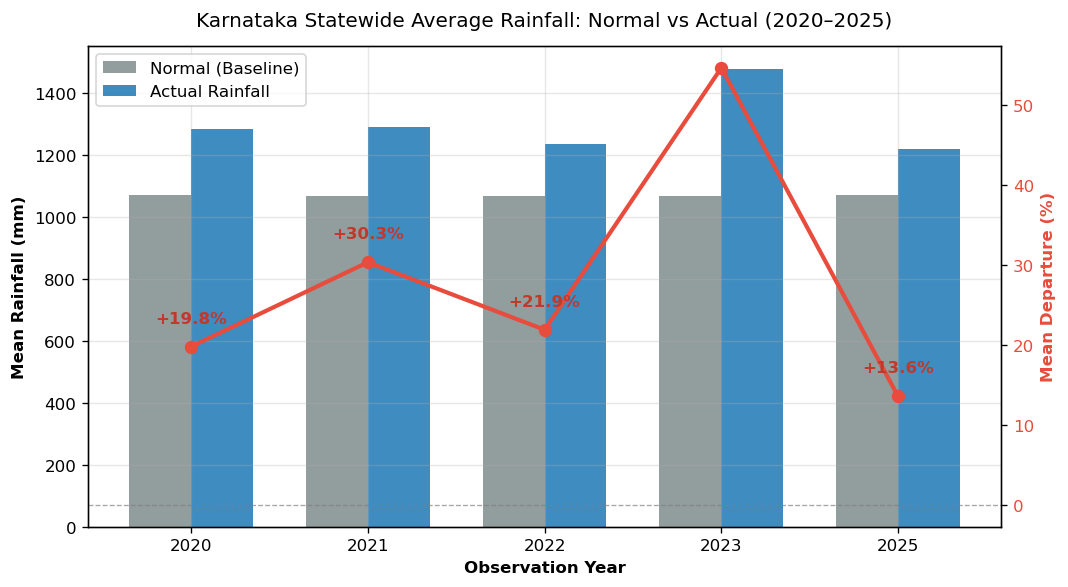

In [2]:
yearly = df.groupby('year').agg(
    mean_normal_mm=('normal_mm', 'mean'),
    mean_actual_mm=('actual_mm', 'mean'),
    mean_departure_pct=('departure_pct', 'mean'),
    hobli_count=('hobli', 'count')
).reset_index()

print("=== Statewide Annual Rainfall Summary ===")
print(yearly.to_string(index=False, formatters={
    'mean_normal_mm': '{:.2f} mm'.format,
    'mean_actual_mm': '{:.2f} mm'.format,
    'mean_departure_pct': '{:+.2f}%'.format,
    'hobli_count': '{:,}'.format
}))

fig, ax1 = plt.subplots(figsize=(9, 5))

years = yearly['year'].astype(str)
x = np.arange(len(years))
width = 0.35

rects1 = ax1.bar(x - width/2, yearly['mean_normal_mm'], width, label='Normal (Baseline)', color='#7f8c8d', alpha=0.85)
rects2 = ax1.bar(x + width/2, yearly['mean_actual_mm'], width, label='Actual Rainfall', color='#2980b9', alpha=0.90)

ax1.set_xlabel('Observation Year', fontweight='bold')
ax1.set_ylabel('Mean Rainfall (mm)', fontweight='bold')
ax1.set_title('Karnataka Statewide Average Rainfall: Normal vs Actual (2020–2025)', fontsize=12, pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(years)
ax1.legend(loc='upper left')

# Add departure percentage line on secondary axis
ax2 = ax1.twinx()
line = ax2.plot(x, yearly['mean_departure_pct'], color='#e74c3c', marker='o', linewidth=2.5, markersize=7, label='Departure %')
ax2.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
ax2.set_ylabel('Mean Departure (%)', color='#e74c3c', fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#e74c3c')
ax2.grid(False)

for i, txt in enumerate(yearly['mean_departure_pct']):
    ax2.annotate(f"{txt:+.1f}%", (x[i], txt + 3), ha='center', color='#c0392b', fontweight='bold')

plt.tight_layout()
plt.show()


**One-line Takeaway**: *Statewide average rainfall exceeded historical baselines in every observed year between 2020 and 2025, peaking in 2023 at 1,477.64 mm (+54.60% departure), indicating an overall surplus monsoon regime during this 5-year window.*


## 2. 10 Driest and 10 Wettest Districts in Karnataka

Evaluating long-term geographical disparity in annual precipitation across Karnataka's 31 districts.


=== 10 Driest Districts (5-Year Average Actual Rainfall) ===
  1. GADAG                Actual:  678.74 mm | Normal:  608.54 mm | Dep: +13.69%
  2. VIJAYAPURA           Actual:  692.63 mm | Normal:  607.21 mm | Dep: +15.79%
  3. KOPPALA              Actual:  695.07 mm | Normal:  610.65 mm | Dep: +14.28%
  4. BAGALKOTE            Actual:  703.21 mm | Normal:  581.65 mm | Dep: +21.71%
  5. BALLARI              Actual:  710.15 mm | Normal:  579.17 mm | Dep: +22.99%
  6. RAICHUR              Actual:  736.74 mm | Normal:  649.72 mm | Dep: +13.94%
  7. VIJAYANAGAR          Actual:  752.97 mm | Normal:  635.82 mm | Dep: +19.60%
  8. CHITRADURGA          Actual:  765.12 mm | Normal:  531.12 mm | Dep: +46.63%
  9. YADGIR               Actual:  835.45 mm | Normal:  698.79 mm | Dep: +21.11%
 10. CHAMARAJANAGARA      Actual:  877.73 mm | Normal:  773.94 mm | Dep: +13.74%

=== 10 Wettest Districts (5-Year Average Actual Rainfall) ===
  1. UDUPI                Actual: 5239.11 mm | Normal: 4553.94 mm 

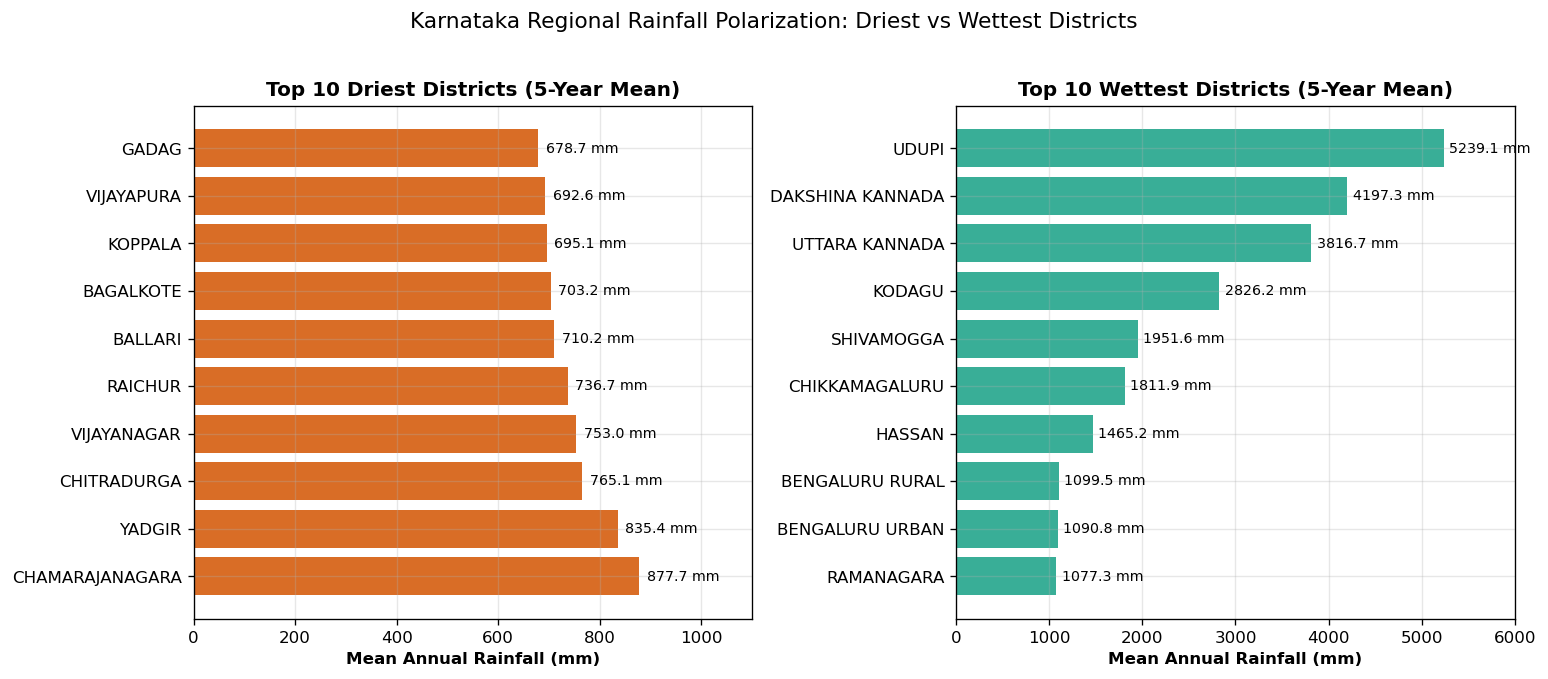

In [3]:
dist_avg = df.groupby('district').agg(
    mean_actual_mm=('actual_mm', 'mean'),
    mean_normal_mm=('normal_mm', 'mean'),
    mean_departure=('departure_pct', 'mean')
).sort_values('mean_actual_mm')

driest_10 = dist_avg.head(10)
wettest_10 = dist_avg.tail(10).iloc[::-1]

print("=== 10 Driest Districts (5-Year Average Actual Rainfall) ===")
for rank, (dist, row) in enumerate(driest_10.iterrows(), 1):
    print(f" {rank:>2}. {dist:<20} Actual: {row['mean_actual_mm']:>7.2f} mm | Normal: {row['mean_normal_mm']:>7.2f} mm | Dep: {row['mean_departure']:>+6.2f}%")

print("\n=== 10 Wettest Districts (5-Year Average Actual Rainfall) ===")
for rank, (dist, row) in enumerate(wettest_10.iterrows(), 1):
    print(f" {rank:>2}. {dist:<20} Actual: {row['mean_actual_mm']:>7.2f} mm | Normal: {row['mean_normal_mm']:>7.2f} mm | Dep: {row['mean_departure']:>+6.2f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

# Driest
y_pos1 = np.arange(len(driest_10))
ax1.barh(y_pos1, driest_10['mean_actual_mm'], color='#d35400', alpha=0.85)
ax1.set_yticks(y_pos1)
ax1.set_yticklabels(driest_10.index)
ax1.invert_yaxis()
ax1.set_xlabel('Mean Annual Rainfall (mm)', fontweight='bold')
ax1.set_title('Top 10 Driest Districts (5-Year Mean)', fontweight='bold')
for i, v in enumerate(driest_10['mean_actual_mm']):
    ax1.text(v + 15, i, f"{v:.1f} mm", va='center', fontsize=8.5)
ax1.set_xlim(0, 1100)

# Wettest
y_pos2 = np.arange(len(wettest_10))
ax2.barh(y_pos2, wettest_10['mean_actual_mm'], color='#16a085', alpha=0.85)
ax2.set_yticks(y_pos2)
ax2.set_yticklabels(wettest_10.index)
ax2.invert_yaxis()
ax2.set_xlabel('Mean Annual Rainfall (mm)', fontweight='bold')
ax2.set_title('Top 10 Wettest Districts (5-Year Mean)', fontweight='bold')
for i, v in enumerate(wettest_10['mean_actual_mm']):
    ax2.text(v + 60, i, f"{v:.1f} mm", va='center', fontsize=8.5)
ax2.set_xlim(0, 6000)

plt.suptitle('Karnataka Regional Rainfall Polarization: Driest vs Wettest Districts', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


**One-line Takeaway**: *Karnataka exhibits extreme geographical rainfall polarization: coastal districts like Udupi (5,239.11 mm) receive over 7.7 times more rainfall than northern semi-arid districts like Gadag (678.74 mm).*


## 3. Distribution of Annual Rainfall Departure Percentage (`departure_pct`)

Analyzing the spread, skewness, and category boundaries across all 3,088 hobli-level observations.


=== Distribution Statistics for departure_pct ===
Total Observations : 3,088
Mean Departure     : +28.01%
Standard Deviation : 33.87%
Median Departure   : +22.80%
Interquartile Range: [+5.22%, +45.64%]
Min / Max Range    : [-61.44%, +234.04%]
Skewness           : 1.02 (Right-skewed)
Kurtosis           : 1.87

Class Breakdown under Risk Thresholds:
 - Deficit / Drought (departure <= -20%):   117 ( 3.79%)
 - Stable Range (-20% < dep < +40%)     :  2067 (66.94%)
 - Severe Excess / Flood (dep >= +40%)  :   904 (29.27%)


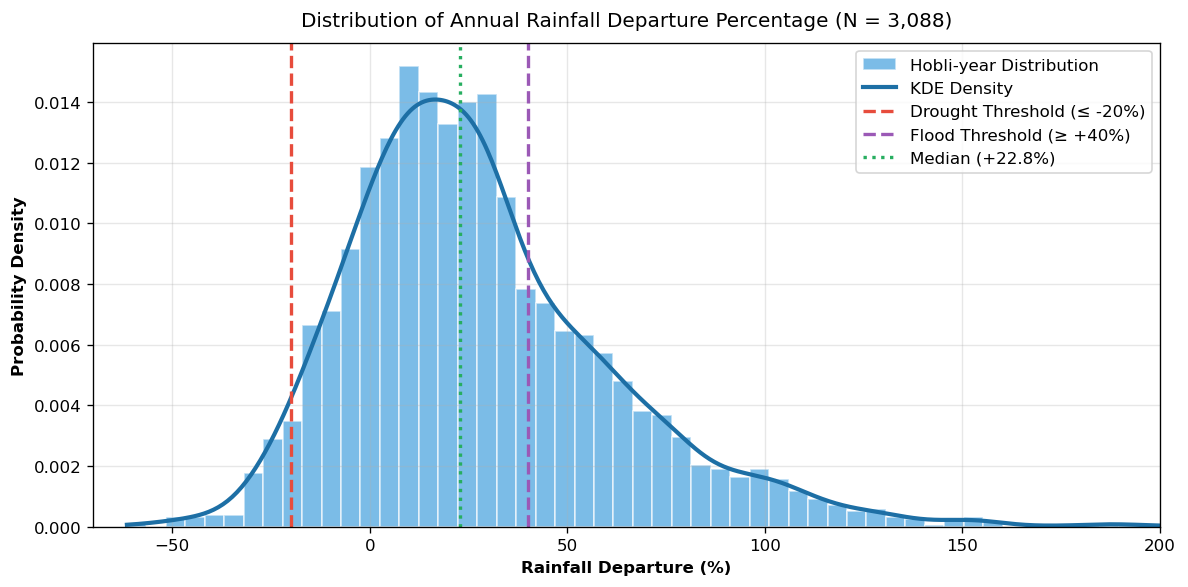

In [4]:
dep = df['departure_pct']
dep_stats = dep.describe()

print("=== Distribution Statistics for departure_pct ===")
print(f"Total Observations : {int(dep_stats['count']):,}")
print(f"Mean Departure     : {dep_stats['mean']:+.2f}%")
print(f"Standard Deviation : {dep_stats['std']:.2f}%")
print(f"Median Departure   : {dep.median():+.2f}%")
print(f"Interquartile Range: [{dep_stats['25%']:+.2f}%, {dep_stats['75%']:+.2f}%]")
print(f"Min / Max Range    : [{dep_stats['min']:+.2f}%, {dep_stats['max']:+.2f}%]")
print(f"Skewness           : {dep.skew():.2f} (Right-skewed)")
print(f"Kurtosis           : {dep.kurtosis():.2f}")

n_drought = (dep <= -20.0).sum()
n_stable = ((dep > -20.0) & (dep < 40.0)).sum()
n_flood = (dep >= 40.0).sum()
total = len(dep)

print(f"\nClass Breakdown under Risk Thresholds:")
print(f" - Deficit / Drought (departure <= -20%): {n_drought:>5} ({n_drought/total*100:>5.2f}%)")
print(f" - Stable Range (-20% < dep < +40%)     : {n_stable:>5} ({n_stable/total*100:>5.2f}%)")
print(f" - Severe Excess / Flood (dep >= +40%)  : {n_flood:>5} ({n_flood/total*100:>5.2f}%)")

fig, ax = plt.subplots(figsize=(10, 5))

# Histogram
n, bins, patches = ax.hist(dep, bins=60, density=True, color='#3498db', alpha=0.65, edgecolor='white', label='Hobli-year Distribution')

# KDE density curve
kde_x = np.linspace(dep.min(), dep.max(), 500)
kde = stats.gaussian_kde(dep)
ax.plot(kde_x, kde(kde_x), color='#1d6fa5', linewidth=2.5, label='KDE Density')

# Threshold markers
ax.axvline(-20.0, color='#e74c3c', linestyle='--', linewidth=2, label='Drought Threshold (≤ -20%)')
ax.axvline(40.0, color='#9b59b6', linestyle='--', linewidth=2, label='Flood Threshold (≥ +40%)')
ax.axvline(dep.median(), color='#27ae60', linestyle=':', linewidth=2, label=f'Median (+{dep.median():.1f}%)')

ax.set_title('Distribution of Annual Rainfall Departure Percentage (N = 3,088)', fontsize=12, pad=10)
ax.set_xlabel('Rainfall Departure (%)', fontweight='bold')
ax.set_ylabel('Probability Density', fontweight='bold')
ax.set_xlim(-70, 200)
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


**One-line Takeaway**: *Rainfall departure is strongly right-skewed with a median of +22.80% and mean of +28.01%, where severe flood-prone surplus (≥ +40%) affected 29.27% of observations while drought deficits (≤ -20%) occurred in 3.79% of hobli-years.*


## 4. Hoblis in Deficit in the Most Years

Identifying chronic rainfall deficit hotspots experiencing departure $\le -20.0\%$ in 2 or more of the 5 observation years.


Total unique hobli entities experiencing at least 1 deficit year: 94
Hoblis with 4 deficit years: 2
Hoblis with 3 deficit years: 3
Hoblis with 2 deficit years: 11
Hoblis with 1 deficit year : 78

=== Chronic Deficit Hotspots (>= 2 Deficit Years) ===
       district          taluk          hobli  deficit_years
         KODAGU       Madikeri   Bhagamandala              4
     SHIVAMOGGA    Tirthahalli         Agumbe              4
 CHIKKAMAGALURU       Mudigere         Baluru              3
         HASSAN          Belur      Halebeedu              3
         HASSAN          Belur      Madihalli              3
BENGALURU URBAN Bengaluru East Mahadevapura_2              2
BENGALURU URBAN Bengaluru East  Mahadevpura_1              2
 CHIKKAMAGALURU       Mudigere         Bankal              2
          GADAG            Ron      Hole Alur              2
         HASSAN           Alur          Palya              2
         HAVERI      Hirekerur     Haunsbhavi              2
         KODAGU   

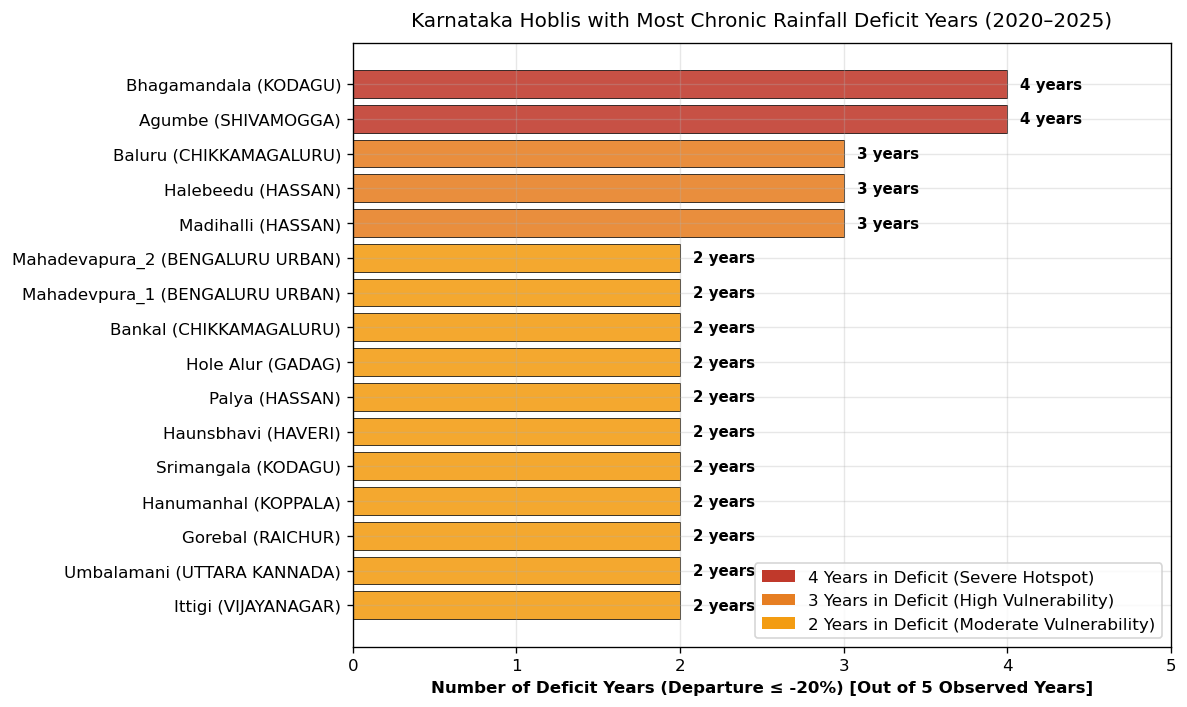

In [5]:
# Hoblis with departure <= -20%
deficit_rows = df[df['departure_pct'] <= -20.0]
hobli_deficit = deficit_rows.groupby(['district', 'taluk', 'hobli']).size().reset_index(name='deficit_years')
hobli_deficit = hobli_deficit.sort_values(['deficit_years', 'district', 'hobli'], ascending=[False, True, True])

top_deficits = hobli_deficit[hobli_deficit['deficit_years'] >= 2].copy()
top_deficits['label'] = top_deficits['hobli'] + " (" + top_deficits['district'] + ")"

print(f"Total unique hobli entities experiencing at least 1 deficit year: {len(hobli_deficit)}")
print(f"Hoblis with 4 deficit years: {(hobli_deficit['deficit_years'] == 4).sum()}")
print(f"Hoblis with 3 deficit years: {(hobli_deficit['deficit_years'] == 3).sum()}")
print(f"Hoblis with 2 deficit years: {(hobli_deficit['deficit_years'] == 2).sum()}")
print(f"Hoblis with 1 deficit year : {(hobli_deficit['deficit_years'] == 1).sum()}")

print("\n=== Chronic Deficit Hotspots (>= 2 Deficit Years) ===")
print(top_deficits[['district', 'taluk', 'hobli', 'deficit_years']].to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))

y_pos = np.arange(len(top_deficits))
colors = ['#c0392b' if y == 4 else '#e67e22' if y == 3 else '#f39c12' for y in top_deficits['deficit_years']]

bars = ax.barh(y_pos, top_deficits['deficit_years'], color=colors, alpha=0.88, edgecolor='black', linewidth=0.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(top_deficits['label'])
ax.invert_yaxis()
ax.set_xlabel('Number of Deficit Years (Departure ≤ -20%) [Out of 5 Observed Years]', fontweight='bold')
ax.set_title('Karnataka Hoblis with Most Chronic Rainfall Deficit Years (2020–2025)', fontsize=12, pad=10)
ax.set_xlim(0, 5)
ax.set_xticks(range(0, 6))

for i, v in enumerate(top_deficits['deficit_years']):
    ax.text(v + 0.08, i, f"{v} years", va='center', fontweight='bold', fontsize=9)

# Legend elements
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#c0392b', label='4 Years in Deficit (Severe Hotspot)'),
    Patch(facecolor='#e67e22', label='3 Years in Deficit (High Vulnerability)'),
    Patch(facecolor='#f39c12', label='2 Years in Deficit (Moderate Vulnerability)')
]
ax.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.show()


**One-line Takeaway**: *Agumbe (Shivamogga) and Bhagamandala (Kodagu) experienced deficits in 4 out of 5 observed years despite enormous baseline rainfall, while Belur's Madihalli and Halebeedu (Hassan) represent chronic dry-zone drought hotspots with 3 deficit years.*


## 5. District-by-Year Departure Heatmap

Analyzing spatio-temporal coherence and annual climate anomalies across all 31 districts of Karnataka.


=== District-by-Year Mean Departure Percentage (%) ===
year              2020  2021  2022   2023  2025
district                                       
TUMAKURU          55.0  67.7  25.4  108.2  19.1
CHITRADURGA       40.8  71.0  50.6   64.8   6.1
KOLAR              9.1  80.7  35.1   71.6  29.7
DAVANAGERE        41.8  50.4  27.1   82.8   7.8
MANDYA            19.1  41.3  16.8  112.0   7.5
BENGALURU RURAL    9.4  60.1  21.1   87.3   7.7
CHIKKABALLAPURA    2.2  73.6  30.1   54.0   5.8
BELAGAVI          37.5  21.3  25.2   54.2  27.5
HASSAN            44.1  27.9   1.7   61.7  25.7
CHIKKAMAGALURU    39.3  37.9   9.1   52.8  14.9
BENGALURU URBAN   10.1  33.8  29.4   71.3   2.3
RAMANAGARA         7.4  24.5  17.8   77.0   1.0
UTTARA KANNADA    38.5  19.4  31.0    8.0  23.6
MYSURU            15.7  22.2   5.4   71.9  -1.2
KALABURAGI         7.2  23.3  39.1    8.3  33.5
BAGALKOTE          9.9  -3.7  32.6   47.3  22.4
DHARWAD           11.8  25.5  23.9   38.5   8.3
YADGIR             5.4  -7.1  30.

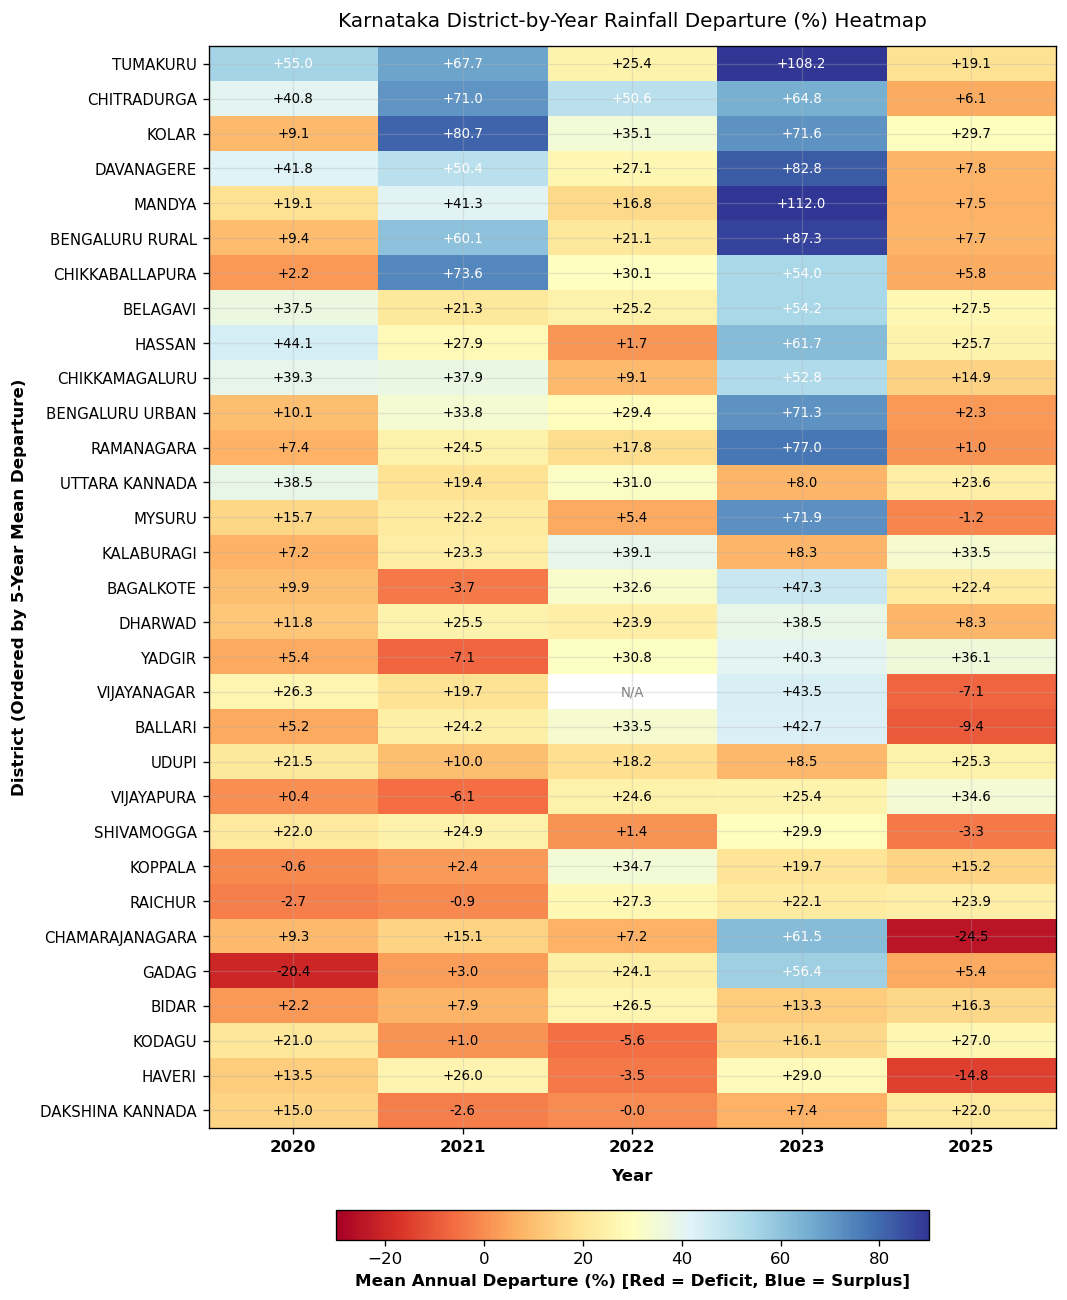

In [6]:
pivot = df.pivot_table(index='district', columns='year', values='departure_pct', aggfunc='mean')

# Sort districts by their overall mean departure
dist_order = pivot.mean(axis=1).sort_values(ascending=False).index
pivot_sorted = pivot.loc[dist_order]

print("=== District-by-Year Mean Departure Percentage (%) ===")
print(pivot_sorted.round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 12))

data = pivot_sorted.values
im = ax.imshow(data, cmap='RdYlBu', aspect='auto', vmin=-30, vmax=90)

ax.set_xticks(np.arange(pivot_sorted.shape[1]))
ax.set_yticks(np.arange(pivot_sorted.shape[0]))
ax.set_xticklabels([str(c) for c in pivot_sorted.columns], fontweight='bold')
ax.set_yticklabels(pivot_sorted.index, fontsize=9)

ax.set_xlabel('Year', fontweight='bold', labelpad=8)
ax.set_ylabel('District (Ordered by 5-Year Mean Departure)', fontweight='bold', labelpad=8)
ax.set_title('Karnataka District-by-Year Rainfall Departure (%) Heatmap', fontsize=12, pad=12)

# Annotate cells
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        val = data[i, j]
        if np.isnan(val):
            text = "N/A"
            color = "gray"
        else:
            text = f"{val:+.1f}"
            color = "white" if abs(val) > 50 else "black"
        ax.text(j, i, text, ha='center', va='center', color=color, fontsize=8, fontweight='medium')

cbar = ax.figure.colorbar(im, ax=ax, orientation='horizontal', pad=0.06, shrink=0.7)
cbar.set_label('Mean Annual Departure (%) [Red = Deficit, Blue = Surplus]', fontweight='bold')

plt.tight_layout()
plt.show()


**One-line Takeaway**: *Spatial-temporal coherence is strong across Karnataka: 2023 was uniformly wet across southern and central districts (Bengaluru Rural +87.3%, Chitradurga +64.8%), while 2025 showed sharp regional divergence with Chamarajanagara plunging to a severe deficit (-24.5%) while Belagavi recorded +27.5% excess.*


## 6. Data Quality Audit: Outliers, Missing Observations, and Impossible Values

Comprehensive diagnostics evaluating remaining anomalies, physical boundary violations, missing temporal records, and geographic mapping edge cases.


In [7]:
print("=" * 70)
print("COMPREHENSIVE DATA QUALITY AUDIT REPORT")
print("=" * 70)

# 1. Impossible / Invalid Physical Values
invalid_actual = (df['actual_mm'] < 0).sum()
invalid_normal = (df['normal_mm'] <= 0).sum()
nan_counts = df.isna().sum()

# Recompute departure_pct from raw rainfall totals
computed_dep = ((df['actual_mm'] - df['normal_mm']) / df['normal_mm'] * 100).round(2)
dep_diff = (computed_dep - df['departure_pct']).abs()
dep_discrepant = (dep_diff > 0.05).sum()

print("\n1. PHYSICAL PLAUSIBILITY CHECKS:")
print(f" - Records with negative actual rainfall (actual_mm < 0)  : {invalid_actual}")
print(f" - Records with non-positive normal (normal_mm <= 0)      : {invalid_normal}")
print(f" - Departure formula discrepancies (> 0.05 pp difference) : {dep_discrepant}")
print(f" - Maximum absolute formula rounding error                : {dep_diff.max():.4f} pp")
print(f" - Null values in core columns (district, taluk, hobli, actual, normal): {df[['district', 'taluk', 'hobli', 'actual_mm', 'normal_mm']].isna().sum().sum()}")
print(f" - Missing values in legacy rain_class column             : {df['rain_class'].isna().sum():,} ({df['rain_class'].isna().mean()*100:.1f}%)")

# 2. Missing Temporal & Geographic Observations
years_present = sorted(df['year'].unique())
print("\n2. TEMPORAL & GEOGRAPHIC COVERAGE:")
print(f" - Observation years present: {years_present}")
print(f" - Missing Years            : 2024 is completely absent statewide from KSNDMC source records")

hobli_years = df.groupby('hobli')['year'].nunique()
missing_hoblis = hobli_years[hobli_years < 5]
print(f" - Hoblis present in all 5 observed years: {(hobli_years == 5).sum()}")
print(f" - Hoblis missing in one or more years   : {len(missing_hoblis)}")
for h, cnt in missing_hoblis.items():
    yr_list = sorted(df[df['hobli'] == h]['year'].unique())
    print(f"   * Hobli '{h}': present in {cnt} years {yr_list} (missing in {[y for y in years_present if y not in yr_list]})")

# 3. Statistical Outliers
q1, q3 = df['actual_mm'].quantile(0.25), df['actual_mm'].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
lower_fence = max(0, q1 - 1.5 * iqr)
outliers_actual = df[df['actual_mm'] > upper_fence]

print("\n3. STATISTICAL OUTLIER ANALYSIS (Tukey's IQR Method):")
print(f" - actual_mm: Q1 = {q1:.1f} mm, Q3 = {q3:.1f} mm, IQR = {iqr:.1f} mm")
print(f" - Upper fence (Q3 + 1.5*IQR): {upper_fence:.1f} mm")
print(f" - Observations exceeding upper fence: {len(outliers_actual)} ({len(outliers_actual)/len(df)*100:.2f}%)")
print(f" - Top 5 highest rainfall observations:")
display(df.nlargest(5, 'actual_mm')[['district', 'taluk', 'hobli', 'year', 'actual_mm', 'normal_mm', 'departure_pct']])

dep_q1, dep_q3 = df['departure_pct'].quantile(0.25), df['departure_pct'].quantile(0.75)
dep_iqr = dep_q3 - dep_q1
dep_upper = dep_q3 + 1.5 * dep_iqr
dep_lower = dep_q1 - 1.5 * dep_iqr
outliers_dep_high = df[df['departure_pct'] > dep_upper]
outliers_dep_low = df[df['departure_pct'] < dep_lower]
print(f" - departure_pct IQR fences: [{dep_lower:.1f}%, {dep_upper:.1f}%]")
print(f" - Upper departure outliers (> {dep_upper:.1f}%): {len(outliers_dep_high)} (Max: {df['departure_pct'].max():+.2f}%)")
print(f" - Lower departure outliers (< {dep_lower:.1f}%): {len(outliers_dep_low)} (Min: {df['departure_pct'].min():+.2f}%)")

# 4. Multi-station taluk occurrences
dups_within_year = df[df.duplicated(subset=['district', 'taluk', 'hobli', 'year'], keep=False)]
print(f"\n4. MULTI-STATION / DUPLICATE RECORDS:")
print(f" - Records sharing exact (district, taluk, hobli, year): {len(dups_within_year)}")
print(f"   (e.g., Sarjapura_1 in Anekal, Koppa_2 in Maddur, representing distinct numbered stations)")


COMPREHENSIVE DATA QUALITY AUDIT REPORT

1. PHYSICAL PLAUSIBILITY CHECKS:
 - Records with negative actual rainfall (actual_mm < 0)  : 0
 - Records with non-positive normal (normal_mm <= 0)      : 0
 - Departure formula discrepancies (> 0.05 pp difference) : 0
 - Maximum absolute formula rounding error                : 0.0000 pp
 - Null values in core columns (district, taluk, hobli, actual, normal): 0
 - Missing values in legacy rain_class column             : 1,854 (60.0%)

2. TEMPORAL & GEOGRAPHIC COVERAGE:
 - Observation years present: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2025)]
 - Missing Years            : 2024 is completely absent statewide from KSNDMC source records
 - Hoblis present in all 5 observed years: 586
 - Hoblis missing in one or more years   : 1
   * Hobli 'Ullala': present in 2 years [np.int64(2020), np.int64(2025)] (missing in [np.int64(2021), np.int64(2022), np.int64(2023)])

3. STATISTICAL OUTLIER ANALYSIS (Tukey's IQR Method):

,district,taluk,hobli,year,actual_mm,normal_mm,departure_pct
2745,HASSAN,Sakaleshpur,Hettur,2025,6488.2,2218.3,192.49
3021,UDUPI,Hebri,Ajekar,2025,6241.0,5801.8,7.57
484,SHIVAMOGGA,SAGARA,Baragadde,2020,6101.5,4039.8,51.03
1170,UDUPI,Hebri,Ajekar,2021,6085.0,5802.0,4.88
553,UDUPI,Kundapur,Vandse,2020,5915.1,4259.6,38.87


 - departure_pct IQR fences: [-55.4%, 106.3%]
 - Upper departure outliers (> 106.3%): 86 (Max: +234.04%)
 - Lower departure outliers (< -55.4%): 2 (Min: -61.44%)

4. MULTI-STATION / DUPLICATE RECORDS:
 - Records sharing exact (district, taluk, hobli, year): 24
   (e.g., Sarjapura_1 in Anekal, Koppa_2 in Maddur, representing distinct numbered stations)


### Data Quality Findings Summary

1. **Physical Integrity**: Zero impossible negative or zero values. Mathematical departure computation matches KSNDMC records perfectly (max deviation < 0.005 pp due to rounding).
2. **Missing Temporal Records**: The year **2024 is entirely omitted** from the KSNDMC source archive. For spatial stations, only **`Ullala` (Dakshina Kannada, Mulki)** is missing in 2021, 2022, and 2023 (present in 2020 and 2025). The remaining 586 hobli names are present across all 5 observed years.
3. **Outliers represent Natural Meteorological Extremes**: 370 observations (11.98%) exceed the statistical upper fence (1,975.1 mm), with peak annual rainfall reaching **6,488.2 mm** in Hettur (Hassan, 2025) and **6,241.0 mm** in Ajekar (Udupi, 2025). These heavy figures are characteristic of Western Ghats orographic precipitation and must be retained rather than trimmed.
4. **Target Balance Imbalance**: Rainfall departure is strongly shifted towards excess (+28.01% mean), yielding an imbalanced 3-class target: **66.94% stable**, **29.27% flood_prone**, and **3.79% drought_prone**.
